In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report,
                             r2_score, mean_absolute_error, mean_squared_error)

In [ ]:
df_raw = pd.read_csv("train.csv")

In [ ]:
print(df_raw.shape)

(1460, 81)


In [ ]:
df_raw.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [ ]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [ ]:
print("Missing values per column (only columns with missing):")
df_raw.isnull().sum()[df_raw.isnull().sum() > 0].sort_values(ascending=False)

Missing values per column (only columns with missing):


,0
PoolQC,1453
MiscFeature,1406
Alley,1369
Fence,1179
MasVnrType,872
FireplaceQu,690
LotFrontage,259
GarageType,81
GarageYrBlt,81
GarageFinish,81


In [ ]:
print("\nMissing % :")
((df_raw.isnull().mean() * 100).round(2)[df_raw.isnull().sum() > 0].sort_values(ascending=False))


Missing % :


,0
PoolQC,99.52
MiscFeature,96.30
Alley,93.77
Fence,80.75
MasVnrType,59.73
FireplaceQu,47.26
LotFrontage,17.74
GarageType,5.55
GarageYrBlt,5.55
GarageFinish,5.55


In [ ]:
print("\nDuplicate rows:", df_raw.duplicated().sum())


Duplicate rows: 0


In [ ]:
print("\nNumeric columns:", len(df_raw.select_dtypes(include="number").columns))


Numeric columns: 38


In [ ]:
print("Text columns:", len(df_raw.select_dtypes(exclude="number").columns))

Text columns: 43


In [ ]:
(df_raw.describe().T)

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


# Keeping only the columns i need

In [ ]:
#dropping 56 unncesscary columns for data training nor power bi
FINAL_PREDICTORS = ["OverallQual", "OverallCond", "ExterQual", "KitchenQual", "BsmtQual", "Neighborhood",
                    "MSZoning", "GrLivArea", "TotalBsmtSF", "LotArea", "YearBuilt", "YearRemodAdd", "YrSold",
                    "GarageCars", "GarageType", "GarageFinish", "BsmtExposure", "BsmtFinType1", "FullBath",
                    "HalfBath", "BedroomAbvGr", "TotRmsAbvGrd", "Fireplaces", "BldgType"]

print("Columns being dropped:", [c for c in df_raw.columns if c not in FINAL_PREDICTORS + ["SalePrice"]])
df = df_raw[FINAL_PREDICTORS + ["SalePrice"]].copy()
print(df.shape)

Columns being dropped: ['Id', 'MSSubClass', 'LotFrontage', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Condition1', 'Condition2', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'MasVnrArea', 'ExterCond', 'Foundation', 'BsmtCond', 'BsmtFinSF1', 'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF', 'LowQualFinSF', 'BsmtFullBath', 'BsmtHalfBath', 'KitchenAbvGr', 'Functional', 'FireplaceQu', 'GarageYrBlt', 'GarageArea', 'GarageQual', 'GarageCond', 'PavedDrive', 'WoodDeckSF', 'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea', 'PoolQC', 'Fence', 'MiscFeature', 'MiscVal', 'MoSold', 'SaleType', 'SaleCondition']
(1460, 25)


# Cleaning

In [ ]:
df.head()

,OverallQual,OverallCond,ExterQual,KitchenQual,BsmtQual,Neighborhood,MSZoning,GrLivArea,TotalBsmtSF,LotArea,...,GarageFinish,BsmtExposure,BsmtFinType1,FullBath,HalfBath,BedroomAbvGr,TotRmsAbvGrd,Fireplaces,BldgType,SalePrice
0,7,5,Gd,Gd,Gd,CollgCr,RL,1710,856,8450,...,RFn,No,GLQ,2,1,3,8,0,1Fam,208500
1,6,8,TA,TA,Gd,Veenker,RL,1262,1262,9600,...,RFn,Gd,ALQ,2,0,3,6,1,1Fam,181500
2,7,5,Gd,Gd,Gd,CollgCr,RL,1786,920,11250,...,RFn,Mn,GLQ,2,1,3,6,1,1Fam,223500
3,7,5,TA,Gd,TA,Crawfor,RL,1717,756,9550,...,Unf,No,ALQ,1,0,3,7,1,1Fam,140000
4,8,5,Gd,Gd,Gd,NoRidge,RL,2198,1145,14260,...,RFn,Av,GLQ,2,1,4,9,1,1Fam,250000


In [ ]:
("Missing BEFORE:"); print(df.isnull().sum()[df.isnull().sum() > 0])

BsmtQual        37
GarageType      81
GarageFinish    81
BsmtExposure    38
BsmtFinType1    37
dtype: int64


In [ ]:
# missing here means "the house has no basement or no garage"
df["BsmtQual"]     = df["BsmtQual"].fillna("None")
df["BsmtExposure"] = df["BsmtExposure"].fillna("None")
df["BsmtFinType1"] = df["BsmtFinType1"].fillna("None")
df["GarageType"]   = df["GarageType"].fillna("None")
df["GarageFinish"] = df["GarageFinish"].fillna("None")

In [ ]:
print("\nMissing AFTER:", df.isnull().sum().sum())


Missing AFTER: 0


In [ ]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()

Duplicate rows: 0


In [ ]:
df.dtypes

,0
OverallQual,int64
OverallCond,int64
ExterQual,object
KitchenQual,object
BsmtQual,object
Neighborhood,object
MSZoning,object
GrLivArea,int64
TotalBsmtSF,int64
LotArea,int64


In [ ]:
df["OverallQual"] = df["OverallQual"].astype(int)
df["OverallCond"] = df["OverallCond"].astype(int)
df["GarageCars"]  = df["GarageCars"].astype(int)

In [ ]:
print("Shape:", df.shape)

Shape: (1460, 25)


# Handling outliers

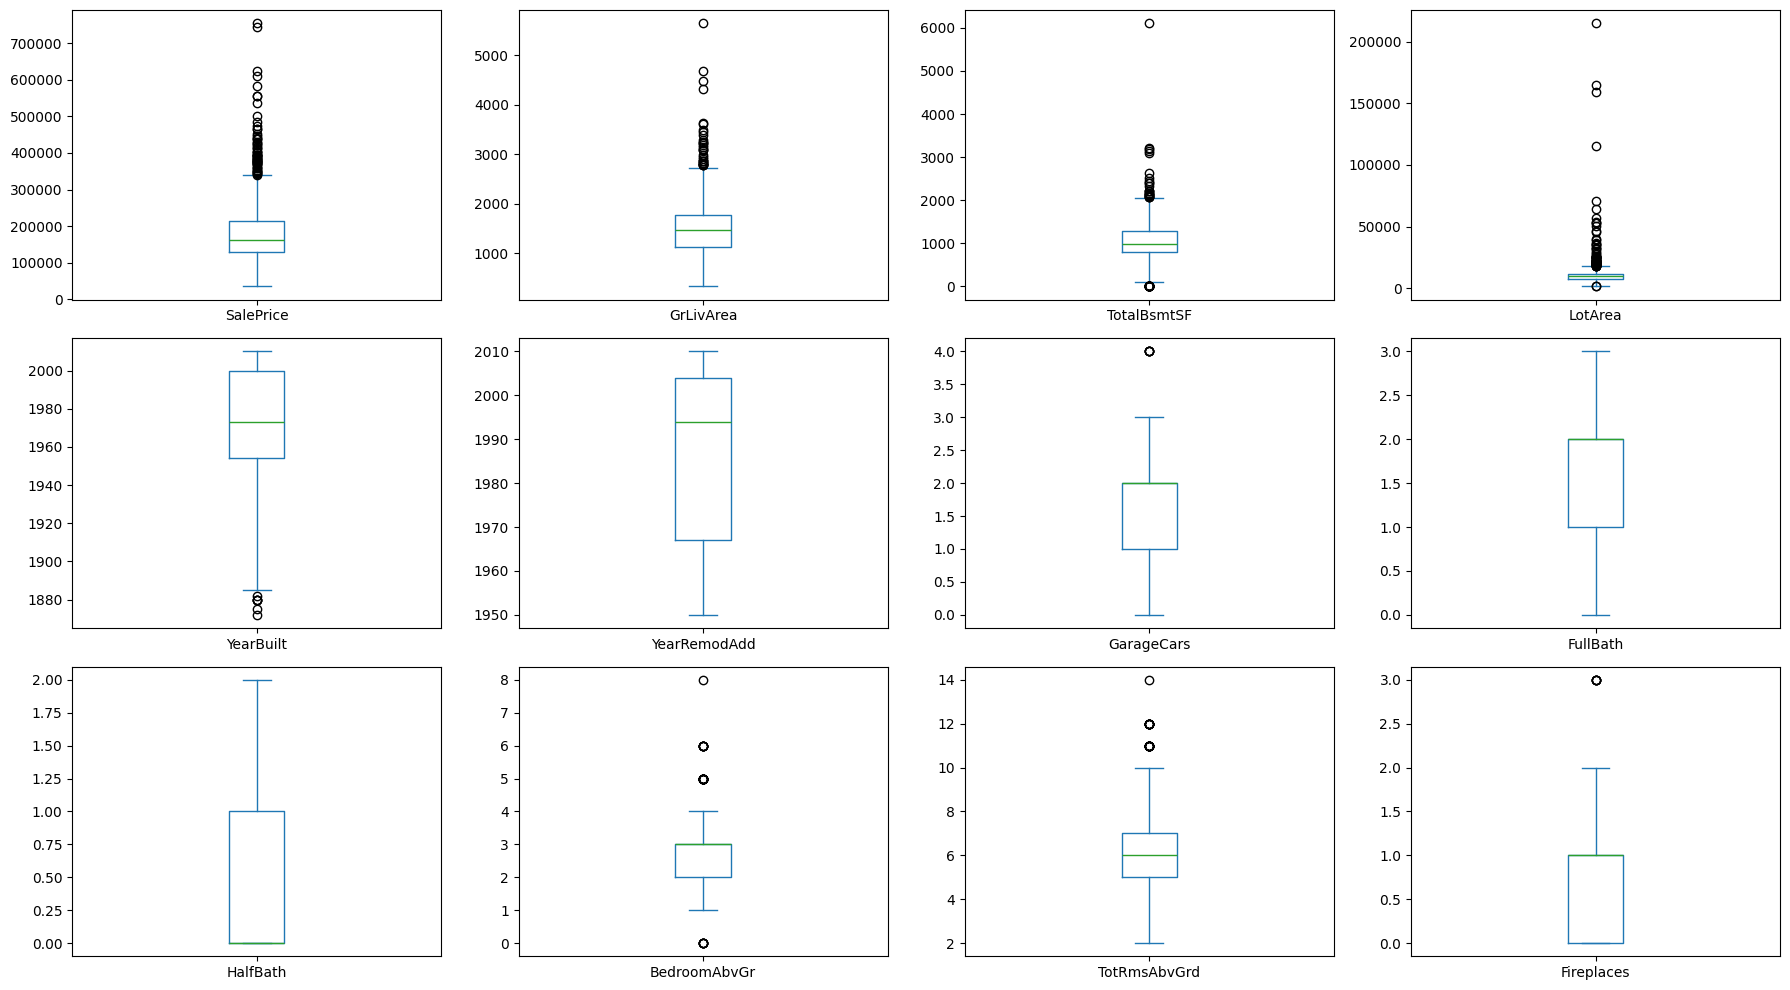

SalePrice      IQR outliers:   61  (fences 3,938 to 340,038)
GrLivArea      IQR outliers:   31  (fences 159 to 2,748)
TotalBsmtSF    IQR outliers:   61  (fences 42 to 2,052)
LotArea        IQR outliers:   69  (fences 1,482 to 17,674)
YearBuilt      IQR outliers:    7  (fences 1,885 to 2,069)
YearRemodAdd   IQR outliers:    0  (fences 1,912 to 2,060)
GarageCars     IQR outliers:    5  (fences -0 to 4)
FullBath       IQR outliers:    0  (fences -0 to 4)
HalfBath       IQR outliers:    0  (fences -2 to 2)
BedroomAbvGr   IQR outliers:   35  (fences 0 to 4)
TotRmsAbvGrd   IQR outliers:   30  (fences 2 to 10)
Fireplaces     IQR outliers:    5  (fences -2 to 2)

Houses with |z| > 3 on at least one variable: 80

Houses larger than 4000 sq ft:
     Neighborhood  OverallQual  GrLivArea  SalePrice
523       Edwards           10       4676     184750
691       NoRidge           10       4316     755000
1182      NoRidge           10       4476     745000
1298      Edwards           10       5642  

In [ ]:
outlier_cols = ["SalePrice", "GrLivArea", "TotalBsmtSF", "LotArea", "YearBuilt", "YearRemodAdd",
                "GarageCars", "FullBath", "HalfBath", "BedroomAbvGr", "TotRmsAbvGrd", "Fireplaces"]

# Boxplots
df[outlier_cols].plot(kind="box", subplots=True, layout=(3, 4), figsize=(18, 10), sharex=False, sharey=False)
plt.tight_layout(); plt.show()

# IQR rule: outlier if below Q1 - 1.5*IQR or above Q3 + 1.5*IQR
for col in outlier_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    n_out = ((df[col] < lower) | (df[col] > upper)).sum()
    print(f"{col:14s} IQR outliers: {n_out:4d}  (fences {lower:,.0f} to {upper:,.0f})")

# Z-score rule: |z| > 3
z = (df[outlier_cols] - df[outlier_cols].mean()) / df[outlier_cols].std()
print("\nHouses with |z| > 3 on at least one variable:", (z.abs() > 3).any(axis=1).sum())

print("\nHouses larger than 4000 sq ft:")
print(df[df["GrLivArea"] > 4000][["Neighborhood", "OverallQual", "GrLivArea", "SalePrice"]])
# no rows are deleted (expensive/large houses are this was due to their area and neighborhoood and other factors
# so they arent actually outliers in this case).

SalePrice has 61 IQR outliers and LotArea 69. 80 houses have |z| > 3. Four houses are over 4000 sq ft. Two are real luxury homes at $755k and $745k. Two Edwards houses (5,642 and 4,676 sq ft at $160k and $185k) look like unusual sales, but I kept them.

# feature engineering

In [ ]:
# ---- Target for Logistic Regression ----
median_price = df["SalePrice"].median()
df["HighPrice"] = (df["SalePrice"] > median_price).astype(int)
print("Median SalePrice:", median_price)
print(df["HighPrice"].value_counts())
print((df["HighPrice"].value_counts(normalize=True) * 100).round(2))

Median SalePrice: 163000.0
HighPrice
0    732
1    728
Name: count, dtype: int64
HighPrice
0    50.14
1    49.86
Name: proportion, dtype: float64


In [ ]:
# ---- Feature engineering (for EDA and Power BI only, NOT used by the models) ----
df["HouseAge"]     = df["YrSold"] - df["YearBuilt"]
df["Remodeled"]    = np.where(df["YearRemodAdd"] > df["YearBuilt"], "Remodeled", "Original")
df["TotalBaths"]   = df["FullBath"] + 0.5 * df["HalfBath"]
df["PricePerSqFt"] = (df["SalePrice"] / df["GrLivArea"]).round(2)
df["PriceTier"]    = np.where(df["HighPrice"] == 1, "High price", "Low price")
df["AgeBand"]      = pd.cut(df["HouseAge"], [-1, 10, 30, 60, 200], labels=["0-10", "11-30", "31-60", "60+"]).astype(str)
df["SizeBand"]     = pd.cut(df["GrLivArea"], [0, 1000, 1500, 2000, 2500, 10000],
                            labels=["0-999", "1000-1499", "1500-1999", "2000-2499", "2500+"]).astype(str)
quality_score = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}
df["BsmtQualOrder"]    = df["BsmtQual"].map(quality_score)
df["KitchenQualOrder"] = df["KitchenQual"].map(quality_score)
df["ExterQualOrder"]   = df["ExterQual"].map(quality_score)

print(df[["HouseAge", "Remodeled", "TotalBaths", "PricePerSqFt", "PriceTier", "AgeBand", "SizeBand"]].head())

   HouseAge  Remodeled  TotalBaths  PricePerSqFt   PriceTier AgeBand  \
0         5   Original         2.5        121.93  High price    0-10   
1        31   Original         2.0        143.82  High price   31-60   
2         7  Remodeled         2.5        125.14  High price    0-10   
3        91  Remodeled         1.0         81.54   Low price     60+   
4         8   Original         2.5        113.74  High price    0-10   

    SizeBand  
0  1500-1999  
1  1000-1499  
2  1500-1999  
3  1500-1999  
4  2000-2499  


# EDA charts

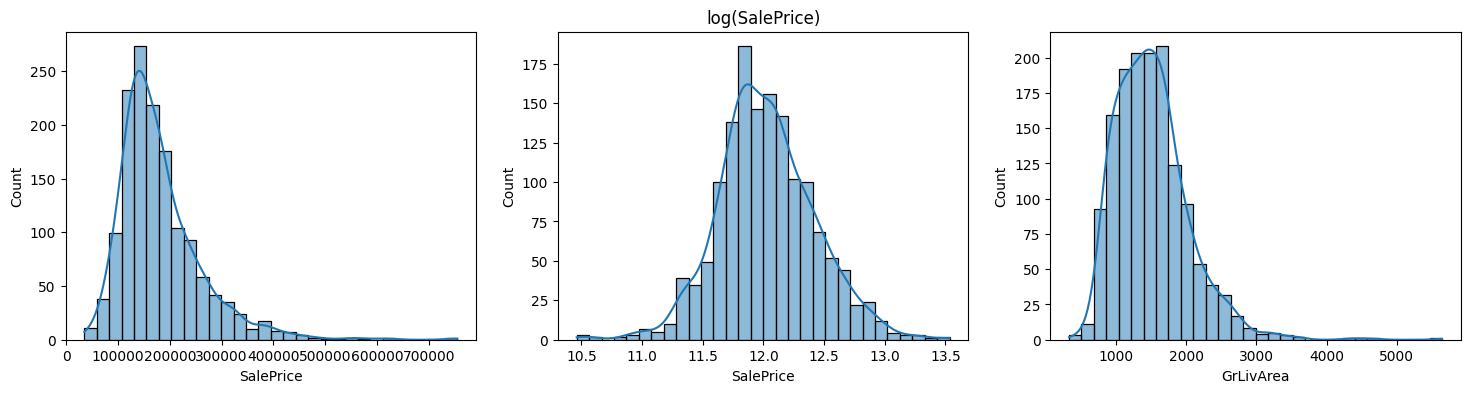

Skewness of SalePrice: 1.88 | after log: 0.12


In [ ]:
# 1) Histograms
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
sns.histplot(df["SalePrice"], bins=30, kde=True, ax=ax[0])
sns.histplot(np.log1p(df["SalePrice"]), bins=30, kde=True, ax=ax[1]); ax[1].set_title("log(SalePrice)")
sns.histplot(df["GrLivArea"], bins=30, kde=True, ax=ax[2])
plt.show()
print("Skewness of SalePrice:", round(df["SalePrice"].skew(), 2), "| after log:", round(np.log1p(df["SalePrice"]).skew(), 2))

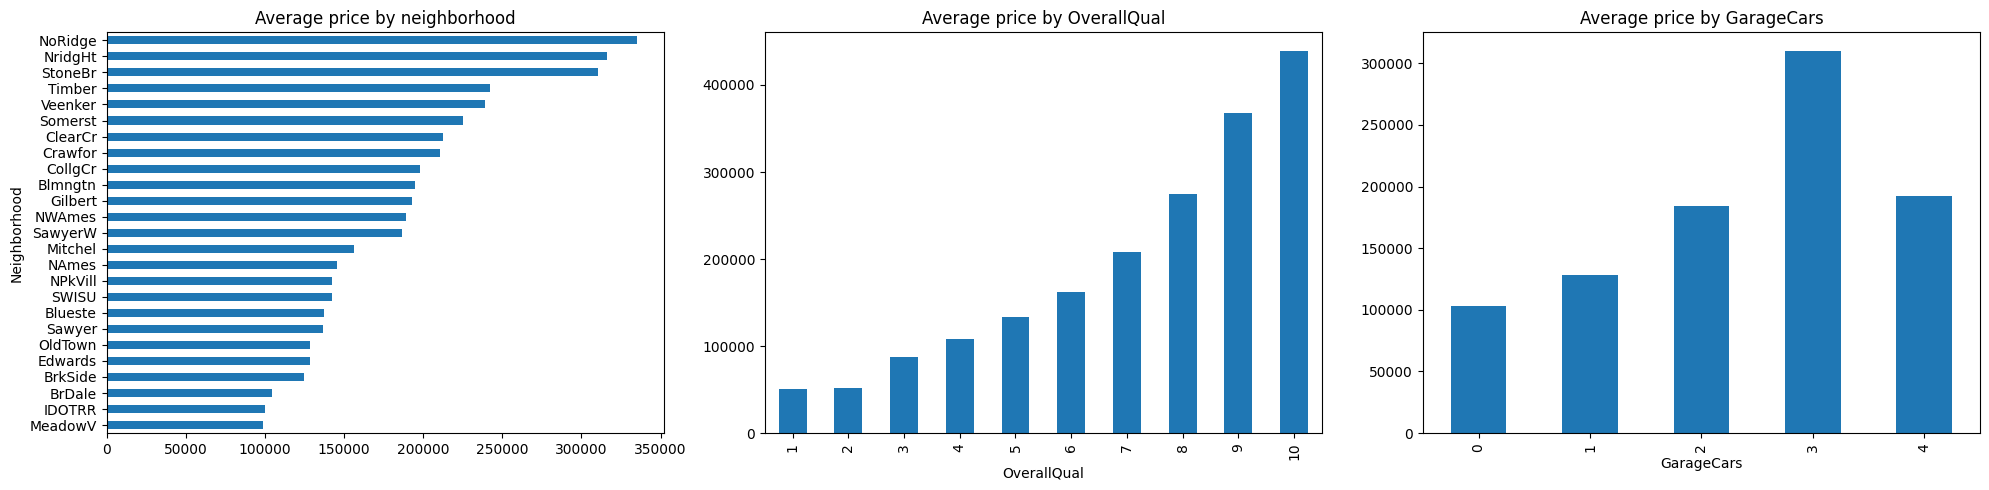

In [ ]:
# 2) Bar charts
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
df.groupby("Neighborhood")["SalePrice"].mean().sort_values().plot(kind="barh", ax=ax[0], title="Average price by neighborhood")
df.groupby("OverallQual")["SalePrice"].mean().plot(kind="bar", ax=ax[1], title="Average price by OverallQual")
df.groupby("GarageCars")["SalePrice"].mean().plot(kind="bar", ax=ax[2], title="Average price by GarageCars")
plt.tight_layout(); plt.show()

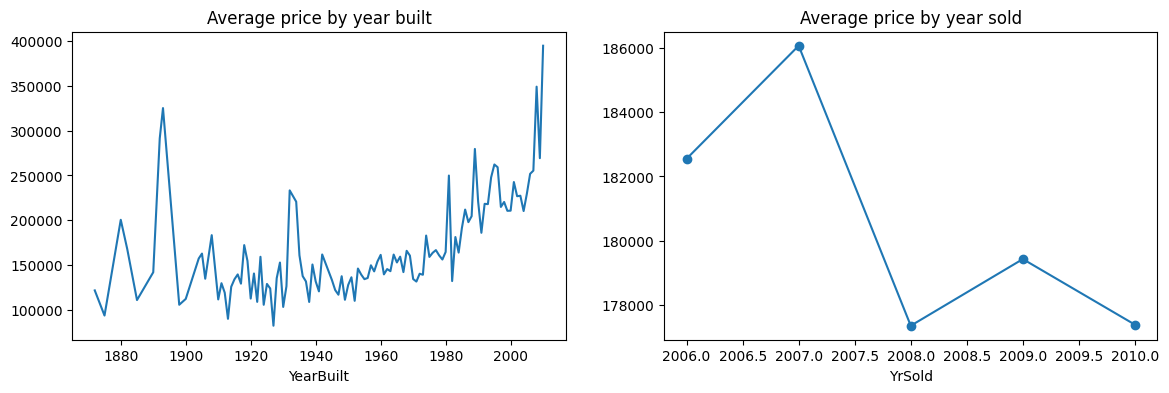

In [ ]:
# 3) Line charts
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df.groupby("YearBuilt")["SalePrice"].mean().plot(ax=ax[0], title="Average price by year built")
df.groupby("YrSold")["SalePrice"].mean().plot(marker="o", ax=ax[1], title="Average price by year sold")
plt.show()

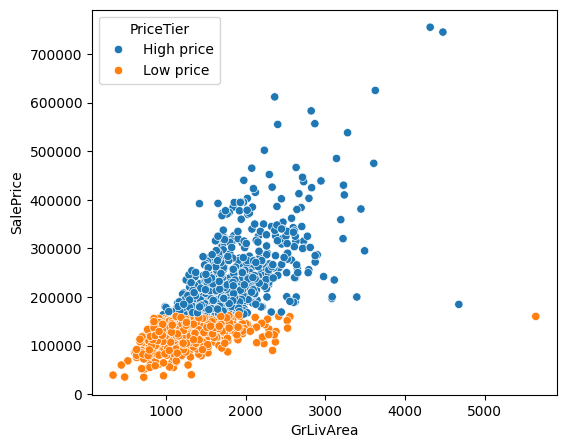

In [ ]:
plt.figure(figsize=(6, 5))
sns.scatterplot(data=df, x="GrLivArea", y="SalePrice", hue="PriceTier")
plt.show()

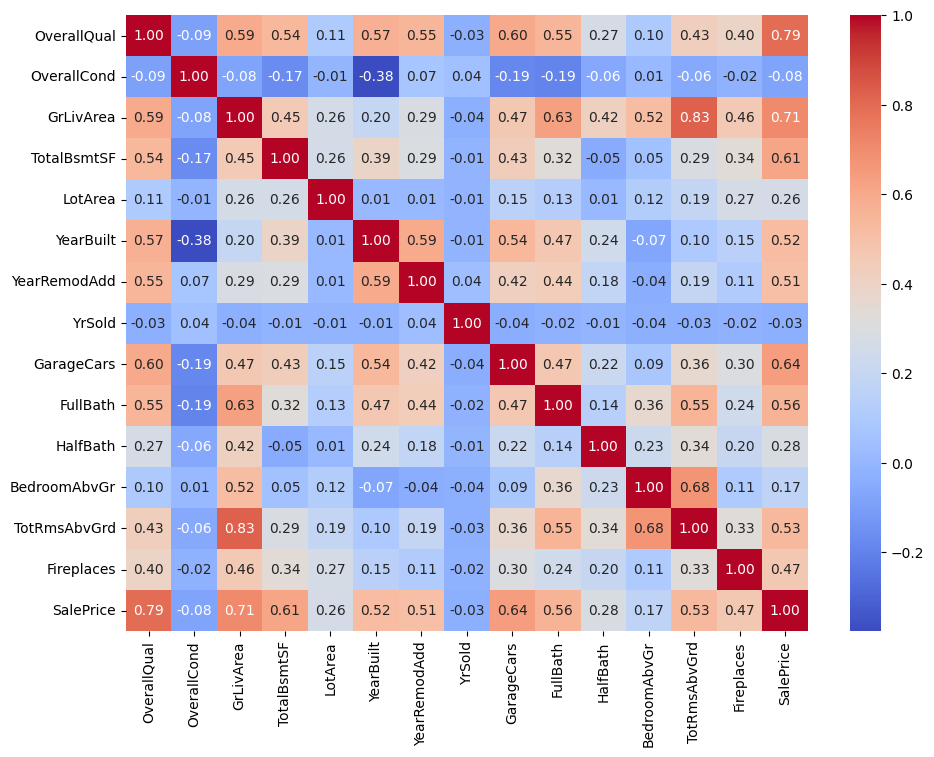

OverallQual     0.79
GrLivArea       0.71
GarageCars      0.64
TotalBsmtSF     0.61
FullBath        0.56
TotRmsAbvGrd    0.53
YearBuilt       0.52
YearRemodAdd    0.51
Fireplaces      0.47
HalfBath        0.28
LotArea         0.26
BedroomAbvGr    0.17
YrSold         -0.03
OverallCond    -0.08
Name: SalePrice, dtype: float64


In [ ]:
# 5) Correlation heatmap
corr = df[FINAL_PREDICTORS + ["SalePrice"]].select_dtypes(include="number").corr()
plt.figure(figsize=(11, 8)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm"); plt.show()
print(corr["SalePrice"].drop("SalePrice").sort_values(ascending=False).round(2))

The main patterns are:

SalePrice skew is about 1.9 and drops to about 0.1 after the log.
The strongest links with price are OverallQual (0.79), GrLivArea (0.71) and GarageCars (0.64).

# Encoing and split

In [ ]:
X = pd.get_dummies(df[FINAL_PREDICTORS], drop_first=True, dtype=int)
y_class = df["HighPrice"]          # for Logistic Regression
y_price = df["SalePrice"]          # for Linear Regression

In [ ]:
# 80/20 split
X_train, X_test, yc_train, yc_test, yp_train, yp_test = train_test_split(
    X, y_class, y_price, test_size=0.2, stratify=y_class, random_state=42)
print("Train:", X_train.shape, "Test:", X_test.shape)

Train: (1168, 75) Test: (292, 75)


In [ ]:
# Winsorize the numeric columns: limits come from the TRAIN set only, then applied to both
num_cols = df[FINAL_PREDICTORS].select_dtypes(include="number").columns
low  = X_train[num_cols].quantile(0.01)
high = X_train[num_cols].quantile(0.99)
X_train = X_train.copy(); X_test = X_test.copy()
X_train[num_cols] = X_train[num_cols].clip(low, high, axis=1)
X_test[num_cols]  = X_test[num_cols].clip(low, high, axis=1)

# Logistic Regression

Best C: 0.5
Cross-validation accuracy: 0.9298

Test accuracy : 0.9384
Precision     : 0.9211
Recall        : 0.9589
F1-score      : 0.9396

Confusion matrix:
 [[134  12]
 [  6 140]]
              precision    recall  f1-score   support

   Low price       0.96      0.92      0.94       146
  High price       0.92      0.96      0.94       146

    accuracy                           0.94       292
   macro avg       0.94      0.94      0.94       292
weighted avg       0.94      0.94      0.94       292



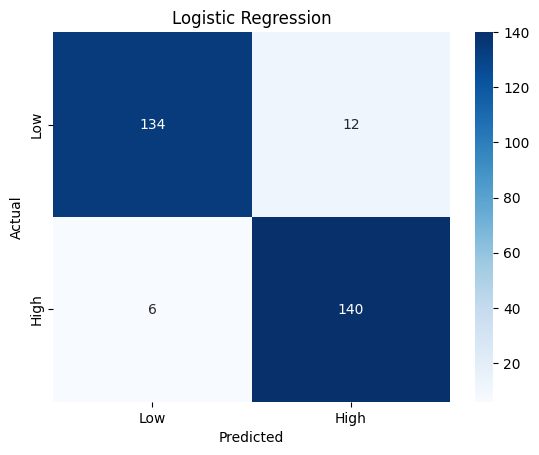


Pushing toward HIGH price:
GrLivArea      1.51
GarageCars     0.94
TotalBsmtSF    0.86
MSZoning_FV    0.80
FullBath       0.52
YearBuilt      0.50
Fireplaces     0.48
OverallCond    0.47
dtype: float64

Pushing toward LOW price:
BldgType_Duplex        -0.47
Neighborhood_MeadowV   -0.46
BsmtExposure_No        -0.41
GarageType_Detchd      -0.39
Neighborhood_Somerst   -0.36
KitchenQual_TA         -0.34
Neighborhood_NPkVill   -0.33
MSZoning_RM            -0.31
dtype: float64


In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
model = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
grid = GridSearchCV(model, {"logisticregression__C": [0.01, 0.05, 0.1, 0.5, 1, 2, 5, 10]},
                    cv=cv, scoring="accuracy")
grid.fit(X_train, yc_train)

print("Best C:", grid.best_params_["logisticregression__C"])
print("Cross-validation accuracy: %.4f" % grid.best_score_)

pred = grid.predict(X_test)
print("\nTest accuracy :", round(accuracy_score(yc_test, pred), 4))
print("Precision     :", round(precision_score(yc_test, pred), 4))
print("Recall        :", round(recall_score(yc_test, pred), 4))
print("F1-score      :", round(f1_score(yc_test, pred), 4))
cm = confusion_matrix(yc_test, pred)
print("\nConfusion matrix:\n", cm)
print(classification_report(yc_test, pred, target_names=["Low price", "High price"]))

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Low", "High"], yticklabels=["Low", "High"])
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title("Logistic Regression"); plt.show()

# Which features matter most (coefficients are comparable because the data is scaled)
coefs = pd.Series(grid.best_estimator_.named_steps["logisticregression"].coef_[0], index=X_train.columns)
print("\nPushing toward HIGH price:"); print(coefs.sort_values(ascending=False).head(8).round(2))
print("\nPushing toward LOW price:");  print(coefs.sort_values().head(8).round(2))

# Linear Regression

Raw SalePrice   R2 0.8697 | RMSE 30,006 | MAE 18,009
log(SalePrice)  R2 0.9105 | RMSE 24,873 | MAE 15,870


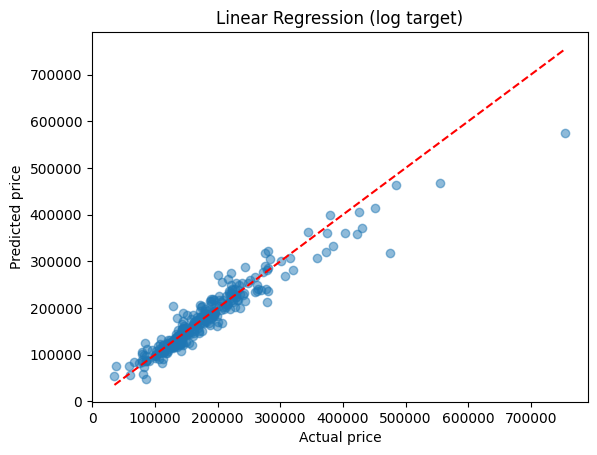

In [ ]:
# Version 1: predict SalePrice directly
lin = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, yp_train)
pred_raw = lin.predict(X_test)

# Version 2: predict log(SalePrice), then convert back with expm1
lin_log = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, np.log1p(yp_train))
pred_log = np.expm1(lin_log.predict(X_test))

for name, p in [("Raw SalePrice", pred_raw), ("log(SalePrice)", pred_log)]:
    print(f"{name:15s} R2 {r2_score(yp_test, p):.4f} | RMSE {np.sqrt(mean_squared_error(yp_test, p)):,.0f} | MAE {mean_absolute_error(yp_test, p):,.0f}")

plt.scatter(yp_test, pred_log, alpha=0.5)
plt.plot([yp_test.min(), yp_test.max()], [yp_test.min(), yp_test.max()], "r--")
plt.xlabel("Actual price"); plt.ylabel("Predicted price"); plt.title("Linear Regression (log target)"); plt.show()

# AI-generated insights

1. Key Findings from Exploratory Data Analysis

   The analysis shows that property characteristics have a strong relationship with house prices. In particular, Overall Quality, above-ground living area (GrLivArea), basement area (TotalBsmtSF), and garage capacity (GarageCars) are important factors associated with house prices.

   The distribution of SalePrice is right-skewed. Applying a logarithmic transformation reduced the skewness substantially, making the target variable more suitable for regression modeling.

   Neighborhood also shows substantial differences in average house prices. NoRidge has the highest average SalePrice at approximately $335,295, while MeadowV has the lowest average at approximately $98,576.

2. Logistic Regression Insights

  The Logistic Regression model was used to classify houses into High Price and Low Price categories.

  The model correctly classified 274 out of 292 unseen test houses, resulting in an accuracy of approximately 93.8%.

  The model identified the following variables as important factors pushing a property toward the High Price category:
  GrLivArea,
  GarageCars,
  TotalBsmtSF

  Other positive contributors included FullBath, YearBuilt, Fireplaces, and OverallCond.

  Factors associated with the Low Price category included:

  BldgType_Duplex,
  Neighborhood_MeadowV,
  BsmtExposure_No,

  The confusion matrix showed 12 false positives and 6 false negatives on the test set.

3. Linear Regression Insights

Two Linear Regression approaches were evaluated: predicting the original SalePrice and predicting log-transformed SalePrice.

The model using the logarithm of SalePrice achieved:

R² = 0.91
RMSE = $24,873
MAE = $15,870

This indicates that the log-target approach explained approximately 91% of the variation in house prices in the test set and had an average absolute prediction error of approximately $15,870.

It also performed better than the model trained directly on SalePrice, which achieved an R² of 0.87 and an MAE of approximately $18,009.

4. Key Business Insights

The analysis suggests that house pricing should pay particular attention to:

Overall quality of the property.
Above-ground living area, which is one of the strongest variables associated with higher prices.
Basement size and garage capacity as additional important property characteristics.
Neighborhood, since average prices differ substantially between neighborhoods.

For pricing analysis, comparing properties within the same neighborhood can provide more meaningful context because neighborhood-level price differences are substantial.

5. Predictive Modeling Value

The two models provide complementary forms of analysis:

Logistic Regression can classify properties into High Price and Low Price categories.
Linear Regression can estimate the expected SalePrice.

Together, these models provide both a classification perspective and a numerical price-prediction perspective.


# Exporting

In [ ]:
from google.colab import files
final_cols = FINAL_PREDICTORS + ["SalePrice", "HighPrice", "HouseAge", "Remodeled", "TotalBaths", "PricePerSqFt",
                                 "PriceTier", "AgeBand", "SizeBand", "BsmtQualOrder", "KitchenQualOrder", "ExterQualOrder"]
df_final = df[final_cols]
print(df_final.shape, "| missing:", df_final.isnull().sum().sum(), "| duplicates:", df_final.duplicated().sum())
df_final.to_csv("ames_housing_final.csv", index=False)
files.download("ames_housing_final.csv")

(1460, 36) | missing: 0 | duplicates: 0


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>